# LGFFE + D4 + Robust AugMix(no-JSD) + MixStyle

**Один новый training recipe**, без абляций или перебора параметров. ResNet50 IMAGENET1K_V2 + прежняя GRU-based LGFFE, полный кадр 256×256. Новая photometric/corruption часть полностью заменяет stronger pipeline; D4 сохраняется. MixStyle после layer1/layer2 работает только в train, включая warmup и замороженные ранние блоки.

AugMix: три ветки, 1–3 случайные операции в каждой, Dirichlet weights + Beta clean/augmented mixing, alpha=1; без JSD и дополнительных forward. Pool: brightness/contrast/gamma, почти grayscale, hue/white balance, autocontrast/equalize, редкие solarize/invert, Gaussian/motion/defocus blur, downscale, JPEG и Gaussian/shot noise. MixStyle p=0.5, alpha=0.1 смешивает channel mean/std объектов batch, без изменения labels или spatial layout.

Train-only, deterministic val без TTA; test не читается. AdamW/cosine и все training параметры прежние: 25 эпох, warmup3, partial layer3+layer4, frozen BN, CE без smoothing, seed42, batch32. Начало — **с ImageNet V2**, не с обученных LGFFE weights. [Описание и источники](../docs/lgffe_robust_recipe.md).


In [1]:
from pathlib import Path
import sys
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT/'src/experiment.py').is_file():
    raise RuntimeError('Откройте notebook из корня проекта или notebooks/')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.experiment import load_config, run_experiment
from src.models.lgffe_checks import check_lgffe
from src.robust_augmix import preview_robust_recipe
from src.training.predict import load_probabilities
from src.utils import get_device, plot_history


## Настройки одного запуска

На Kaggle укажите RAW_DIR. Для обучения установите RUN_TRAINING=True. Synthetic preflight запускается обязательно перед training; RUN_PREFLIGHT=True позволяет проверить модель отдельно. Размер batch уменьшайте только при нехватке памяти; image_size сохраняйте 256.


In [7]:
CONFIG = 'configs/resnet50_lgffe_robust_augmix_mixstyle.json'
EXP_ID = 'resnet50_lgffe_robust_augmix_mixstyle_001'
DEVICE = 'auto'
BATCH_SIZE = 32
NUM_WORKERS = 2 if get_device(DEVICE).type == 'cuda' else 0
CPU_THREADS = 4
RAW_DIR = PROJECT_ROOT/'data/raw'  # либо Path('/kaggle/input/<dataset>')
RUN_PREVIEW = True
RUN_PREFLIGHT = True
RUN_TRAINING = False
PREVIEW_CLASS = 'commercial_area'
PREVIEW_INDEX = 0
PREVIEW_SEED = 42

if get_device(DEVICE).type == 'cpu':
    torch.set_num_threads(CPU_THREADS)
config = load_config(CONFIG, project_root=PROJECT_ROOT)
config['data'].update(raw_dir=str(RAW_DIR), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
config['training']['device'] = DEVICE
print(f'{EXP_ID} | {get_device(DEVICE)} | batch={BATCH_SIZE}; train only, no test')


resnet50_lgffe_robust_augmix_mixstyle_001 | cpu | batch=32; train only, no test


## Preview: исходный train и 11 случайных вариантов

Можно менять только выбранное train-изображение и seed просмотра. D4 не меняет pixels интерполяцией; AugMix смешивает деградированные ветки с исходным кадром. Некоторые варианты поэтому остаются почти исходными — это часть рецепта. Здесь нужно визуально оценить, что тяжёлые эффекты сохраняют распознаваемость. Preview не является измерением качества будущей модели.


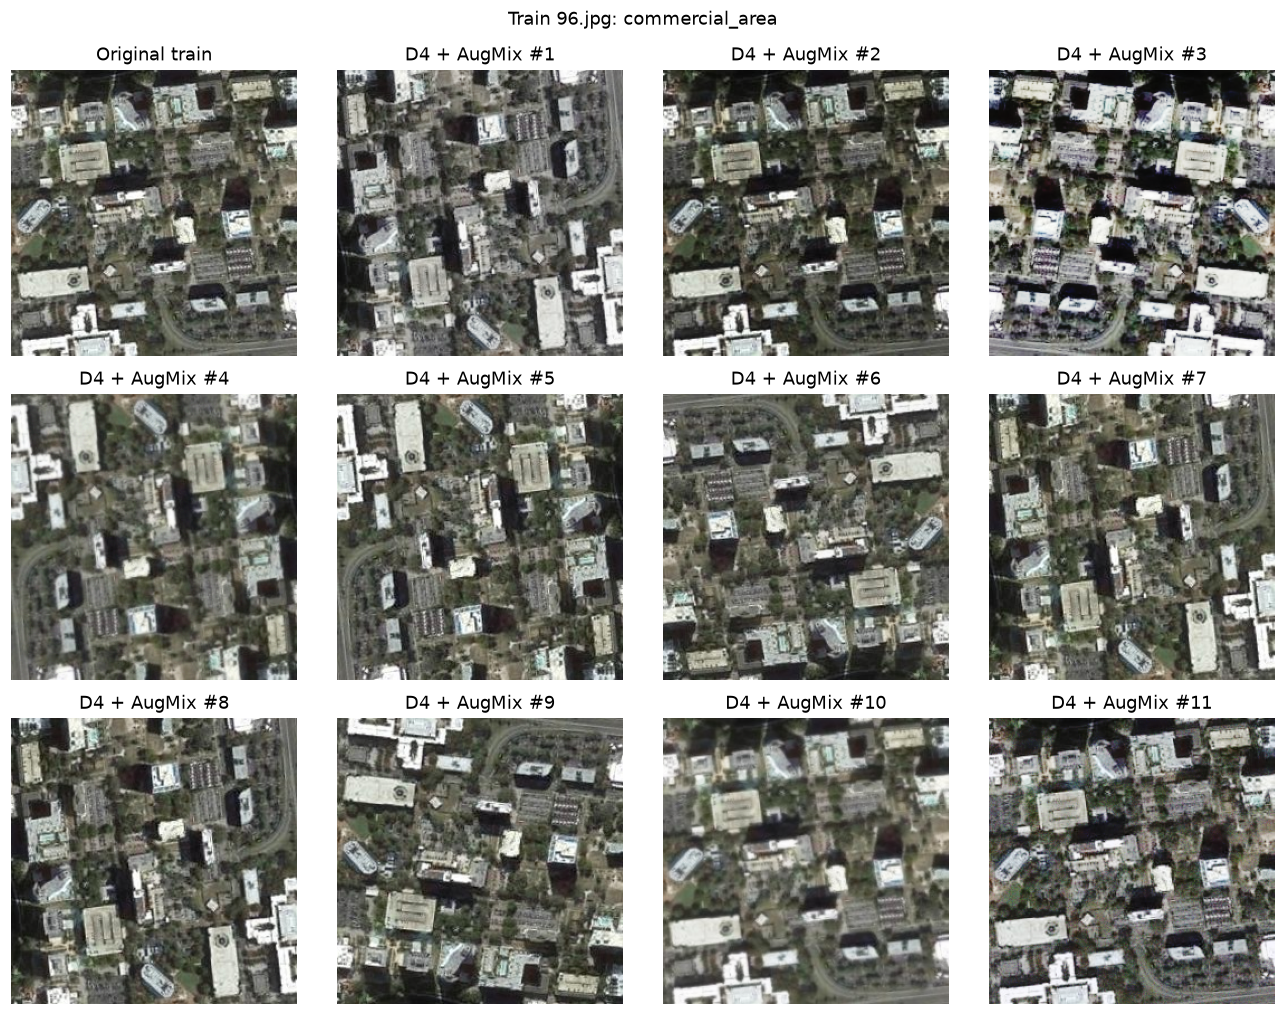

In [3]:
if RUN_PREVIEW:
    classes = pd.read_csv(RAW_DIR/'classes.csv')
    train = pd.read_csv(RAW_DIR/'train.csv', dtype={'id': str})
    matching = classes.loc[classes.class_name.eq(PREVIEW_CLASS), 'label']
    if matching.empty:
        raise ValueError(f'Неизвестный PREVIEW_CLASS: {PREVIEW_CLASS}')
    examples = train.loc[train.label.eq(matching.iloc[0])].reset_index(drop=True)
    row = examples.iloc[PREVIEW_INDEX]
    image_path = (RAW_DIR/'train'/row.id).resolve()
    if not image_path.is_relative_to((RAW_DIR/'train').resolve()):
        raise ValueError('Image ID выходит за train directory')
    with Image.open(image_path) as source:
        image = source.convert('RGB')
    figure = preview_robust_recipe(image, config['data'], count=11, seed=PREVIEW_SEED)
    figure.suptitle(f'Train {row.id}: {PREVIEW_CLASS}', y=1.02)
    plt.show()


## Synthetic preflight и один training run

Настоящая torchvision ResNet50, синтетический batch, forward/backward, attention, warmup/partial, frozen BN и optimizer groups. Без скачивания pretrained weights и без реальных данных. В training run pretrained V2 загружается отдельно: нужен интернет либо заранее подготовленный torch cache. Eval отключает обе MixStyle и все случайные image transforms.


In [4]:
preflight = None
if RUN_PREFLIGHT or RUN_TRAINING:
    preflight = check_lgffe(config, device=DEVICE, batch_size=4)
    print(json.dumps(preflight, indent=2, ensure_ascii=False))
else:
    print('Preflight для отдельного просмотра выключен; при training он выполнится автоматически.')


Preflight для отдельного просмотра выключен; при training он выполнится автоматически.


In [5]:
result = None
if RUN_TRAINING:
    assert preflight is not None
    result = run_experiment(config, exp_id=EXP_ID, project_root=PROJECT_ROOT,
                            show_plots=True, predict_test=False)
else:
    print('Обучение выключено. На Kaggle установите RUN_TRAINING=True.')


Обучение выключено. На Kaggle установите RUN_TRAINING=True.


## Результат после обучения

Показывает единственный run, learning curves и короткое сравнение с уже сохранёнными stronger50 и LGFFE stronger. Это не сетка экспериментов. Сравнение происходит на одинаковых val IDs без TTA. Более низкая уверенность в ошибках сама по себе не означает улучшение Accuracy или calibration.


,exp_id,best_epoch,val_accuracy,train_time_min
0,resnet50_lgffe_robust_augmix_mixstyle_001,17,0.957082,33.448643


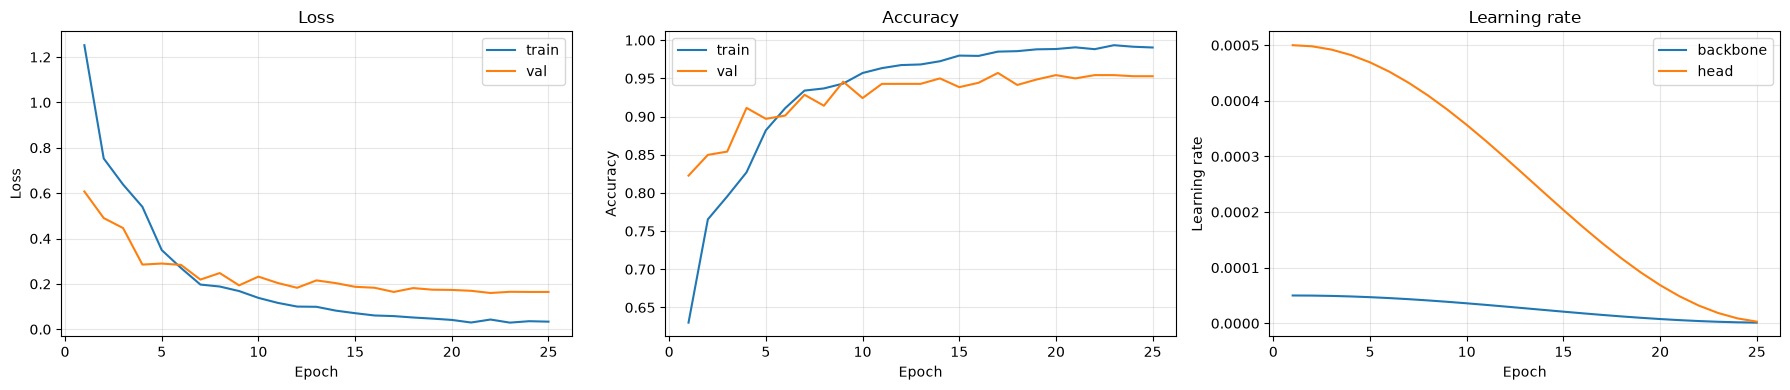

,model,correct,accuracy,fixed_by_robust,new_errors_robust
0,LGFFE robust,669,0.957082,NaN,NaN
1,stronger50,675,0.965665,10.0,16.0
2,LGFFE stronger,668,0.955651,13.0,12.0


Исправлено: 10; новых ошибок: 16; общих ошибок: 14


,id,true_label,stronger50_label,lgffe_label,stronger50_confidence,lgffe_confidence
2,45.jpg,5,3,5,0.650349,0.953888
14,233.jpg,2,2,9,0.999276,0.599651
72,1617.jpg,6,19,6,0.899272,0.914416
76,1685.jpg,8,2,8,0.900393,0.995811
91,1951.jpg,17,17,7,0.594571,0.863966
142,2927.jpg,11,11,10,0.977998,0.728385
152,3072.jpg,18,18,12,0.753848,0.919937
160,3201.jpg,10,10,16,0.950278,0.385646
195,3986.jpg,10,10,11,0.883505,0.395722
236,4761.jpg,17,3,7,0.845540,0.692994


Логи: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\logs\resnet50_lgffe_robust_augmix_mixstyle_001
Веса: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\models\resnet50_lgffe_robust_augmix_mixstyle_001
Вероятности: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\predictions\resnet50_lgffe_robust_augmix_mixstyle_001\val_probabilities.npz
Training row записана в experiments.csv; test inference не запускался.


In [10]:
logs = PROJECT_ROOT/'artifacts/logs'/EXP_ID
predictions = PROJECT_ROOT/'artifacts/predictions'/EXP_ID
if not (logs/'summary.json').is_file():
    print('Новый recipe ещё не обучен. После Kaggle training выполните эту ячейку повторно.')
else:
    summary = json.loads((logs/'summary.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'exp_id': EXP_ID, **summary}]))
    if result is None:
        plot_history(pd.read_csv(logs/'history.csv'), show=True)
    candidate = load_probabilities(predictions/'val_probabilities.npz').table(include_scores=True)
    new_ok = candidate.label.to_numpy() == candidate.true_label.to_numpy()
    rows = [{'model': 'LGFFE robust', 'correct': int(new_ok.sum()), 'accuracy': float(new_ok.mean())}]
    for name, run in [('stronger50', 'resnet50_partial_domain_shift_stronger_001'),
                      ('LGFFE stronger', 'resnet50_lgffe_domain_shift_stronger_001')]:
        path = PROJECT_ROOT/'artifacts/predictions'/run/'val_probabilities.npz'
        if not path.is_file():
            continue
        old = load_probabilities(path).table(include_scores=True)
        if set(old.id) != set(candidate.id):
            raise ValueError('Val IDs отличаются; сравнение запрещено')
        old = old.set_index('id').loc[candidate.id].reset_index()
        if not (old.true_label.to_numpy() == candidate.true_label.to_numpy()).all():
            raise ValueError('Val labels отличаются; сравнение запрещено')
        old_ok = old.label.to_numpy() == old.true_label.to_numpy()
        rows.append({'model': name, 'correct': int(old_ok.sum()), 'accuracy': float(old_ok.mean()),
                     'fixed_by_robust': int((~old_ok & new_ok).sum()),
                     'new_errors_robust': int((old_ok & ~new_ok).sum())})
    display(pd.DataFrame(rows))

    baseline_path = PROJECT_ROOT / 'artifacts/predictions/resnet50_partial_domain_shift_stronger_001/val_probabilities.npz'
    if baseline_path.is_file():
        baseline = load_probabilities(baseline_path).table(include_scores=True)
        baseline = baseline.set_index('id').reindex(candidate.id).reset_index()
        if baseline.label.isna().any() or len(baseline) != len(candidate):
            raise ValueError('Baseline/candidate val IDs не совпадают')
        if not (baseline.true_label.to_numpy() == candidate.true_label.to_numpy()).all():
            raise ValueError('Baseline/candidate val targets не совпадают')
        old_ok = baseline.label.to_numpy() == baseline.true_label.to_numpy()
        new_ok = candidate.label.to_numpy() == candidate.true_label.to_numpy()
        print(f'Исправлено: {int((~old_ok & new_ok).sum())}; новых ошибок: {int((old_ok & ~new_ok).sum())}; '
                f'общих ошибок: {int((~old_ok & ~new_ok).sum())}')
        changed = pd.DataFrame({'id': candidate.id, 'true_label': candidate.true_label,
                                'stronger50_label': baseline.label, 'lgffe_label': candidate.label,
                                'stronger50_confidence': baseline.confidence, 'lgffe_confidence': candidate.confidence})
        display(changed[changed.stronger50_label != changed.lgffe_label].head(30))
    else:
        print('Baseline val_probabilities.npz отсутствует; сохранённый результат LGFFE показан выше.')
        
    print(f'Логи: {logs}')
    print(f'Веса: {PROJECT_ROOT/"artifacts/models"/EXP_ID}')
    print(f'Вероятности: {predictions/"val_probabilities.npz"}')
    print('Training row записана в experiments.csv; test inference не запускался.')


## Linear SVM поверх замороженных LGFFE features

Отдельная проверка классификатора **после анализа neural run**. Используется best.pt `resnet50_lgffe_robust_augmix_mixstyle_001`. Модель в eval, requires_grad=False, extraction в inference_mode: backbone, GRU и attention не переобучаются; MixStyle, AugMix, D4 и TTA выключены.

Извлекается `fused_features`: concat **global+local (4096)** непосредственно до всей classification head. Это не hidden512 и не logits. Train и val имеют один детерминированный image transform. Train-only mean/std стандартизируют features; эти же параметры применяются к val.

Один 20-классовый linear SVM в PyTorch, без sklearn: MultiMarginLoss(p=1) + L2. Фиксировано **C=1**; objective `0.5*||W||² + C*sum_i sum_{j≠y} max(0, 1+s_j-s_y)`. Bias не регуляризуется. Full-batch LBFGS, max_iter200, только train objective; val не используется для tuning, early stopping или fitting. Число optimizer evaluations может превышать число iterations из-за line search. Это не нейросетевой fine-tuning.

Сохранённые scores SVM **не являются вероятностями**. Сравнение с исходной головой использует её обычные softmax predictions без TTA на тех же val IDs.


In [ ]:
from src.lgffe_svm import extract_lgffe_features, run_lgffe_svm, show_svm_results

RUN_SVM = False  # включить один раз, когда best.pt доступен
SVM_CHECKPOINT = PROJECT_ROOT/'artifacts/models/resnet50_lgffe_robust_augmix_mixstyle_001/best.pt'
SVM_RUN_ID = 'resnet50_lgffe_robust_augmix_mixstyle_001_svm_001'
SVM_FEATURE_CACHE = PROJECT_ROOT/'artifacts/predictions/resnet50_lgffe_robust_augmix_mixstyle_001_frozen_features'
SVM_C = 1.0  # заранее фиксировано; не подбирать по val
SVM_MAX_ITER = 200
SVM_FIT_DEVICE = 'cpu'  # features извлекаются на DEVICE; linear optimization может работать на CPU

print(f'Frozen source: {SVM_CHECKPOINT}')
print(f'Checkpoint доступен: {SVM_CHECKPOINT.is_file()}')
print('Neural training выключен; test не читается. Для SVM не включайте RUN_TRAINING.')


### Извлечение features и один fitting

Первый запуск проходит по всем train/val кадрам один раз. На CPU extraction может занять заметное время; на Kaggle GPU он быстрее. Полный feature cache сохраняется отдельно и повторно используется только при совпадении source/data hashes. Если SVM run уже существует, оставьте RUN_SVM=False и смотрите отчёты ниже — веса не перезаписываются.

Если checkpoint отсутствует локально, укажите путь к сохранённому best.pt на Kaggle или скопируйте его в указанную директорию. Neural training повторять не требуется.


In [ ]:
svm_paths = None
if RUN_SVM:
    if not SVM_CHECKPOINT.is_file():
        raise FileNotFoundError(f'Нужен сохранённый best.pt: {SVM_CHECKPOINT}')
    cache = extract_lgffe_features(PROJECT_ROOT, SVM_CHECKPOINT, SVM_FEATURE_CACHE,
                                   raw_dir=RAW_DIR, device=DEVICE, batch_size=BATCH_SIZE,
                                   num_workers=NUM_WORKERS, cpu_threads=CPU_THREADS)
    svm_paths = run_lgffe_svm(PROJECT_ROOT, cache, SVM_RUN_ID, C=SVM_C,
                              max_iter=SVM_MAX_ITER, device=SVM_FIT_DEVICE)
else:
    print('SVM fitting выключен; для запуска установите RUN_SVM=True.')


### Val Accuracy, confusion matrices, ошибки классов и изменившиеся ответы

Таблица changed_objects содержит все изменившиеся ответы, включая случаи, где обе модели ошиблись. `fixed` и `new_error` считаются по истинным val labels. Отчёты и confusion matrices сохраняются отдельно от исходного neural run. Никаких результатов до фактического fitting не предполагается.


In [ ]:
svm_logs = PROJECT_ROOT/'artifacts/logs'/SVM_RUN_ID
if (svm_logs/'summary.json').is_file():
    changed_objects = show_svm_results(PROJECT_ROOT, SVM_RUN_ID)
    parameters = json.loads((svm_logs/'parameters.json').read_text(encoding='utf-8'))
    print(f'Optimizer iterations={parameters["iterations"]}, evaluations={parameters["closure_evaluations"]}; '
          f'train accuracy={parameters["train_accuracy"]:.4f}; C={parameters["C"]}')
    print('Техническая остановка optimizer не гарантирует достижение точного optimum hinge objective.')
    print(f'SVM weights: {PROJECT_ROOT/"artifacts/models"/SVM_RUN_ID/"linear_svm.pt"}')
    print(f'Изменившиеся объекты: {PROJECT_ROOT/"artifacts/predictions"/SVM_RUN_ID/"changed_objects.csv"}')
else:
    print('SVM ещё не обучен; neural checkpoint и старые результаты сохранены.')
